In [ ]:
# --- 0. Setup: find the repo root wherever this notebook runs from ------------------------
import os, sys, json, unittest
from pathlib import Path
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline" / "run_experiment.py").exists())
sys.path.insert(0, str(ROOT / "pipeline"))
os.chdir(ROOT)                                  # so relative paths in configs resolve
print("Repo root:", ROOT)

import run_experiment, evaluate_final, summarise
from obpevo import config as C, core, instances, baselines

Repo root: c:\Users\nicho\Documents\github\dsa4212-project\code


In [2]:
# --- 6. Real LLM check with Gemini (free tier) ---------------------------------------------
# Check pipeline using pipeline.yaml first (12 evals, population 4)
# 6a. API key: from .env in the repo root (GEMINI_API_KEY=...), or paste it below. Never commit it.
try:
    from dotenv import load_dotenv                      # %pip install python-dotenv
    load_dotenv(ROOT / ".env")
except ImportError:
    pass
# os.environ["GEMINI_API_KEY"] = "AIza..."             # alternative: paste here, clear before sharing
# assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is not set"
assert os.environ.get("OPENROUTER_API_KEY"), "OPENROUTER_API_KEY is not set"

from obpevo.llm import make_backend

In [3]:
# # One call through the same wrapper the pipeline uses
# import tempfile
# from obpevo.llm import make_backend, LoggedLLM
# cfg = C.load("configs/eoh_baseline.yaml")
# log = Path(tempfile.mkdtemp()) / "calls.csv"
# wrapped = LoggedLLM(make_backend(cfg["llm"]), log, price_in_per_1m=0.3, price_out_per_1m=2.5)
# print(wrapped.draw_sample("Say hi")[:100])
# display(pd.read_csv(log))           # one row: status ok, token_source api

import tempfile
from obpevo.llm import make_backend, LoggedLLM
cfg = C.load("configs/eoh_baseline.yaml", llm="openrouter-gemini-3.5-flash-lite")
log = Path(tempfile.mkdtemp()) / "calls.csv"
w = LoggedLLM(make_backend(cfg["llm"]), log, cfg["llm"]["price_in_per_1m"], cfg["llm"]["price_out_per_1m"])
print(w.draw_sample("Say hi")[:100]); display(pd.read_csv(log))     # status ok, token_source api, cost > 0

Hi!


,call,t_start,latency_s,prompt_tokens,completion_tokens,token_source,cum_tokens,cost_usd,status,prompt_chars,response_chars
0,1,1.793462e+09,1.128,2,2,api,4,0.0,ok,6,3


In [4]:
## Quick check of the pipeline
run_experiment.main("configs/pipecheck.yaml", llm="openrouter-gemini-3.5-flash-lite", force=True)

LLM: openrouter-gemini-3.5-flash-lite (openrouter, $0.3/$2.5 per 1M in/out) | budget: {'max_evals': 12, 'max_tokens': 60000, 'max_minutes': 8, 'name': 'check'} | results: results/pipecheck__openrouter-gemini-3.5-flash-lite
[pipecheck__openrouter-gemini-3.5-flash-lite] 1 runs | budget {'max_evals': 12, 'max_tokens': 60000, 'max_minutes': 8, 'name': 'check'} | train=train (6 instances)
           eoh seed0: 12 evals (11 ok, 1 err, 0 timeout) | 15 calls, 8,474 tokens | best train excess 0.0489 | method_finished | 0.14 min
Wrote C:\Users\nicho\Documents\github\dsa4212-project\code\results\pipecheck__openrouter-gemini-3.5-flash-lite\runs_index.csv (1 runs)


,experiment,label,method,seed,llm_name,llm_provider,llm_model,budget_name,mode,train_set,...,n_evals,n_unique_programs,n_ok,n_error,n_timeout,n_crash,n_calls_not_evaluated,best_eval,best_train_excess,best_code_hash
0,pipecheck__openrouter-gemini-3.5-flash-lite,eoh,eoh,0,openrouter-gemini-3.5-flash-lite,openrouter,google/gemini-3.5-flash-lite,check,funsearch,train,...,12,8,11,1,0,0,3,2,0.048907,41e5fb5c303a


In [5]:
# --- 7. EoH baseline: several seeds in one go on the real instances ------------------------
# Per seed: ~300 evals, ~300 LLM calls, ~35 min, ~US$0.17 notional. Needs step 0 and the API key cell first.
CONFIG = "configs/eoh_baseline.yaml"
SEEDS = [0,1,2]
FORCE = False                # False: keep finished seeds (seed 0 is skipped, runs 1 and 2: ~70 min, ~600 calls)
                             # True: redo all of SEEDS, e.g. seed 0 on the pinned LLM4AD (~105 min, ~900 calls)
ARGS = {"llm": "openrouter-gemini-3.5-flash-lite"}                    # {} = model and budget from the config -> results/eoh_baseline/
                             # another model: {"llm": "gemini-3.8-flash"} -> its own folder
cfg = C.load(CONFIG, **ARGS)
out = C.results_dir(cfg)
print("LLM:", cfg["llm"]["name"], "| budget:", cfg["budget"], "| results:", out.name, "| seeds:", SEEDS, "| force:", FORCE)

LLM: openrouter-gemini-3.5-flash-lite | budget: {'max_evals': 300, 'max_tokens': 1500000, 'max_minutes': 120, 'name': 'full'} | results: eoh_baseline__openrouter-gemini-3.5-flash-lite | seeds: [0, 1, 2] | force: False


In [6]:
# 7a. Best Fit on the real training set: the number EoH has to beat
train_v0 = instances.load_set(run_experiment.ensure_instances(cfg) / f"{cfg['evaluation']['train_set']}.npz")
bf_v0 = -core.score(core.evaluate(baselines.best_fit, train_v0, cfg["evaluation"]["mode"]))
print(f"{len(train_v0)} training instances | Best Fit train excess: {bf_v0:.3%}")

32 training instances | Best Fit train excess: 4.751%


In [ ]:
# 7b. The search: seeds run one after another; the cell blocks until all finish
idx = run_experiment.main(CONFIG, seeds=SEEDS, force=FORCE, **ARGS)

# 7c. How each run went
rows, curves = [], {}
for seed in SEEDS:
    run = out / "eoh" / f"seed{seed}"
    s = json.loads((run / "summary.json").read_text())
    ev, calls = pd.read_csv(run / "evals.csv"), pd.read_csv(run / "llm_calls.csv")
    exc = pd.to_numeric(ev.get("train_excess"), errors="coerce")          # numeric even if the run has no evals
    ok_exc = exc[ev.get("status") == "ok"] if len(ev) else exc
    rows.append(dict(seed=seed, stop=s["stop_reason"], minutes=s["wall_minutes"], evals=len(ev),
                     ok=int((ev.get("status") == "ok").sum()) if len(ev) else 0,
                     calls=len(calls), failed_calls=int((calls.status != "ok").sum()),
                     cost_usd=calls.cost_usd.sum(), best_eval=s["best_eval"],
                     best_train_pct=None if s["best_train_excess"] is None else 100 * s["best_train_excess"],
                     # search diagnostics: is the LLM exploring, or rewriting Best Fit?
                     tie_bf_pct=100 * (abs(ok_exc - bf_v0) < 1e-9).mean() if len(ok_exc) else None,
                     distinct_scores=ok_exc.round(6).nunique(),
                     collapse_pct=100 * (ok_exc > 0.5).mean() if len(ok_exc) else None,   # >50% excess, e.g. one item per bin
                     llm4ad=json.loads((run / "config.json").read_text())["versions"]["llm4ad_commit"][:7]))
    best = exc.cummin().ffill() * 100                                  # best-so-far curve, for the table below
    if best.notna().any():                                             # skip runs with no successful evaluation
        step = max(1, len(ev) // 10)
        curves[f"seed{seed}"] = best.iloc[step - 1::step].values
    if s["stop_reason"] == "budget:llm_errors":                        # API kept failing, e.g. free-tier daily quota
        print(f"seed {seed} API errors:", calls[calls.status != "ok"].status.str[:120].value_counts().head(2).to_dict())

runs = pd.DataFrame(rows)
runs["vs_best_fit_pp"] = runs.best_train_pct - 100 * bf_v0            # negative = EoH better
display(runs.round(3))
ok = runs.best_train_pct.dropna()
beat = (ok < 100 * bf_v0 - 1e-9).sum()                                 # strictly better; exact ties don't count
print(f"best train excess across seeds: {ok.mean():.3f} ± {ok.std():.3f}% (Best Fit {100 * bf_v0:.3f}%) | "
      f"{beat}/{len(ok)} seeds beat Best Fit | total notional cost ${runs.cost_usd.sum():.3f}")

# Best-so-far at 10 points through each run: when did each seed improve?
display(pd.DataFrame({k: pd.Series(v) for k, v in curves.items()}).T
        .rename(columns=lambda i: f"{(i + 1) * 10}%").round(3))

for seed in SEEDS:                                                     # each seed's best heuristic
    prog = out / "eoh" / f"seed{seed}" / "best_program.py"
    print(f"\n===== seed {seed} =====\n" + (prog.read_text() if prog.exists() else "(no successful candidate)"))

LLM: openrouter-gemini-3.5-flash-lite (openrouter, $0.3/$2.5 per 1M in/out) | budget: {'max_evals': 300, 'max_tokens': 1500000, 'max_minutes': 120, 'name': 'full'} | results: results/eoh_baseline__openrouter-gemini-3.5-flash-lite
[eoh_baseline__openrouter-gemini-3.5-flash-lite] 3 runs | budget {'max_evals': 300, 'max_tokens': 1500000, 'max_minutes': 120, 'name': 'full'} | train=train (32 instances)
           eoh seed0: 300 evals (297 ok, 3 err, 0 timeout) | 301 calls, 207,232 tokens | best train excess 0.0475 | budget:evals | 17.82 min
           eoh seed1: 300 evals (297 ok, 3 err, 0 timeout) | 301 calls, 192,140 tokens | best train excess 0.0475 | budget:evals | 13.55 min
           eoh seed2: 300 evals (297 ok, 3 err, 0 timeout) | 301 calls, 195,041 tokens | best train excess 0.0451 | budget:evals | 19.05 min
Wrote C:\Users\nicho\Documents\github\dsa4212-project\code\results\eoh_baseline__openrouter-gemini-3.5-flash-lite\runs_index.csv (3 runs)


,seed,stop,minutes,evals,ok,calls,failed_calls,cost_usd,best_eval,best_train_pct,llm4ad,vs_best_fit_pp
0,0,budget:evals,17.82,300,297,301,0,0.178,1,4.751,unknown,-0.000
1,1,budget:evals,13.55,300,297,301,0,0.159,1,4.751,unknown,-0.000
2,2,budget:evals,19.05,300,297,301,0,0.156,66,4.507,unknown,-0.244


best train excess across seeds: 4.670 ± 0.141% (Best Fit 4.751%) | 3/3 seeds beat Best Fit | total notional cost $0.493


,10%,20%,30%,40%,50%,60%,70%,80%,90%,100%
seed0,4.751,4.751,4.751,4.751,4.751,4.751,4.751,4.751,4.751,4.751
seed1,4.751,4.751,4.751,4.751,4.751,4.751,4.751,4.751,4.751,4.751
seed2,4.554,4.554,4.507,4.507,4.507,4.507,4.507,4.507,4.507,4.507



===== seed 0 =====
# eval 1, train excess 0.04751

import numpy as np

def priority(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.
    Args:
        item: Size of item to be added to the bin.
        bins: Array of capacities for each bin.
    Return:
        Array of same size as bins with priority score of each bin.
    """
    remaining = bins - item
    return np.where(remaining >= 0, -remaining, -np.inf)



===== seed 1 =====
# eval 1, train excess 0.04751

import numpy as np

def priority(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.
    Args:
        item: Size of item to be added to the bin.
        bins: Array of capacities for each bin.
    Return:
        Array of same size as bins with priority score of each bin.
    """
    residual = bins - item
    return np.where(residual >= 0, 1.0 / (residual + 1e-5), -np.inf)



===== seed 2 =====
# e

[eoh_baseline__openrouter-gemini-3.5-flash-lite] 24 program x set jobs on ['val', 'test_id_5k', 'test_size_10k', 'test_cap500', 'test_cap500_scaled', 'test_shape_k1.5', 'test_shape_k5', 'test_uniform']
               eoh seed0 val                ok
               eoh seed0 test_id_5k         ok
               eoh seed0 test_size_10k      ok
               eoh seed0 test_cap500        ok
               eoh seed0 test_cap500_scaled ok
               eoh seed0 test_shape_k1.5    ok
               eoh seed0 test_shape_k5      ok
               eoh seed0 test_uniform       ok
               eoh seed1 val                ok
               eoh seed1 test_id_5k         ok
               eoh seed1 test_cap500        ok
               eoh seed1 test_cap500_scaled ok
               eoh seed1 test_size_10k      ok
               eoh seed1 test_shape_k1.5    ok
               eoh seed1 test_shape_k5      ok
               eoh seed1 test_uniform       ok
               eoh seed2 val                ok

set,test_cap500,test_cap500_scaled,test_id_5k,test_shape_k1.5,test_shape_k5,test_size_10k,test_uniform,val
label,,,,,,,,
almost_worst_fit,0.90,8.82,8.44,6.63,10.47,8.34,8.30,8.24
best_fit,0.50,4.44,4.17,1.34,8.25,3.95,5.07,4.73
eoh,0.50 ± 0.00,4.48 ± 0.07,4.11 ± 0.10,1.32 ± 0.02,8.27 ± 0.03,3.93 ± 0.03,4.97 ± 0.17,4.63 ± 0.17
first_fit,0.50,4.80,4.55,1.58,8.45,4.27,5.57,5.23
next_fit,4.62,29.43,29.20,30.05,24.32,28.96,31.71,28.63
worst_fit,2.34,13.72,13.14,12.27,12.95,13.01,14.46,13.34


,set,runs,delta_vs_bf_pp,best_run,worst_run,win_vs_bf
40,test_cap500,3,0.00000,0.00498,0.00498,0.00000
41,test_cap500_scaled,3,0.03988,0.04444,0.04564,0.00000
42,test_id_5k,3,-0.05949,0.03990,0.04169,0.26667
43,test_shape_k1.5,3,-0.01333,0.01299,0.01339,0.20000
44,test_shape_k5,3,0.01939,0.08254,0.08312,0.06667
45,test_size_10k,3,-0.01665,0.03900,0.03950,0.26667
46,test_uniform,3,-0.09918,0.04773,0.05070,0.26667
47,val,3,-0.09970,0.04429,0.04728,0.26667


# eoh_baseline__openrouter-gemini-3.5-flash-lite: summary tables

Budget per run: {'max_evals': 300, 'max_tokens': 1500000, 'max_minutes': 120, 'name': 'full'}

## Search runs

| label | runs | evals/run | ok % | error % | timeout % | LLM calls/run | tokens/run | cost USD (total) | minutes/run | best train excess % (mean ± sd) |
|---|---|---|---|---|---|---|---|---|---|---|
| eoh | 3 | 300.0 | 99.0 | 1.0 | 0.0 | 301.0 | 198138 | 0.493 | 16.81 | 4.670 ± 0.141 |

## Held-out sets: excess over lower bound (%), mean ± sd across seeds

| label | val | test_id_5k | test_size_10k | test_cap500 | test_cap500_scaled | test_shape_k1.5 | test_shape_k5 | test_uniform |
|---|---|---|---|---|---|---|---|---|
| eoh | 4.63 ± 0.17 | 4.11 ± 0.10 | 3.93 ± 0.03 | 0.50 ± 0.00 | 4.48 ± 0.07 | 1.32 ± 0.02 | 8.27 ± 0.03 | 4.97 ± 0.17 |
| first_fit | 5.23 | 4.55 | 4.27 | 0.50 | 4.80 | 1.58 | 8.45 | 5.57 |
| best_fit | 4.73 | 4.17 | 3.95 | 0.50 | 4.44 | 1.34 | 8.25 | 5.07 |
| worst_fit | 13.34 | 13.14 | 13.01 |

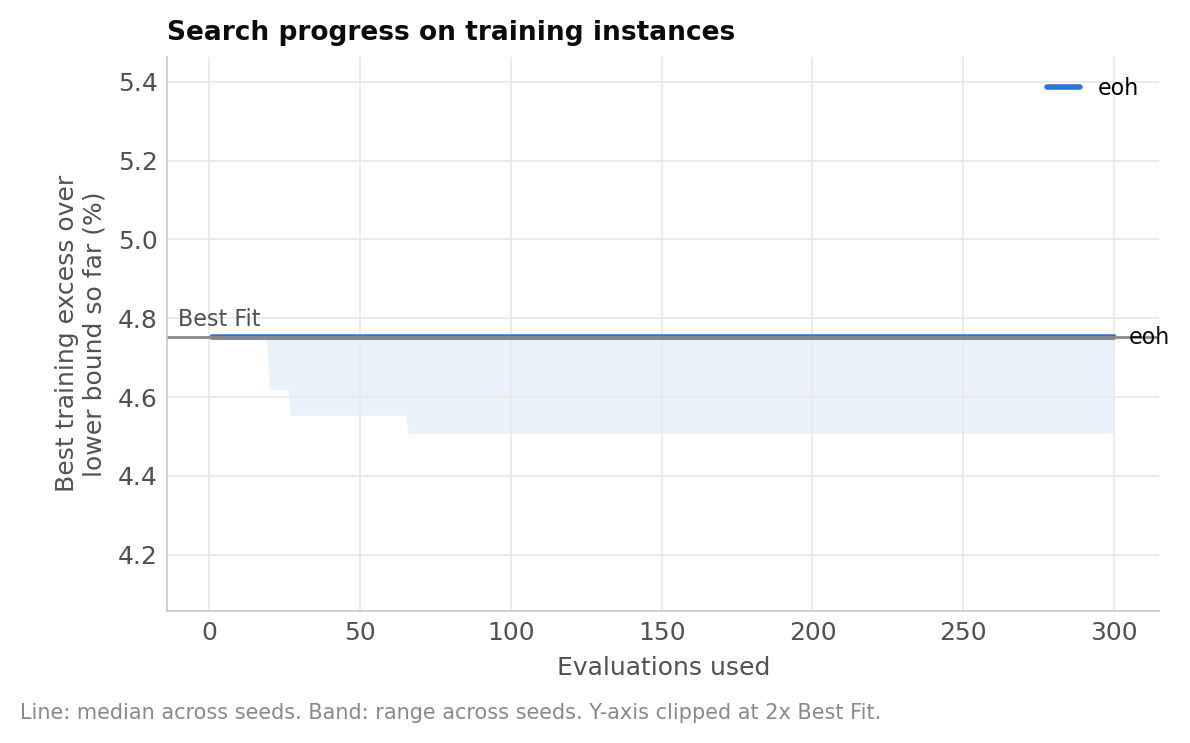

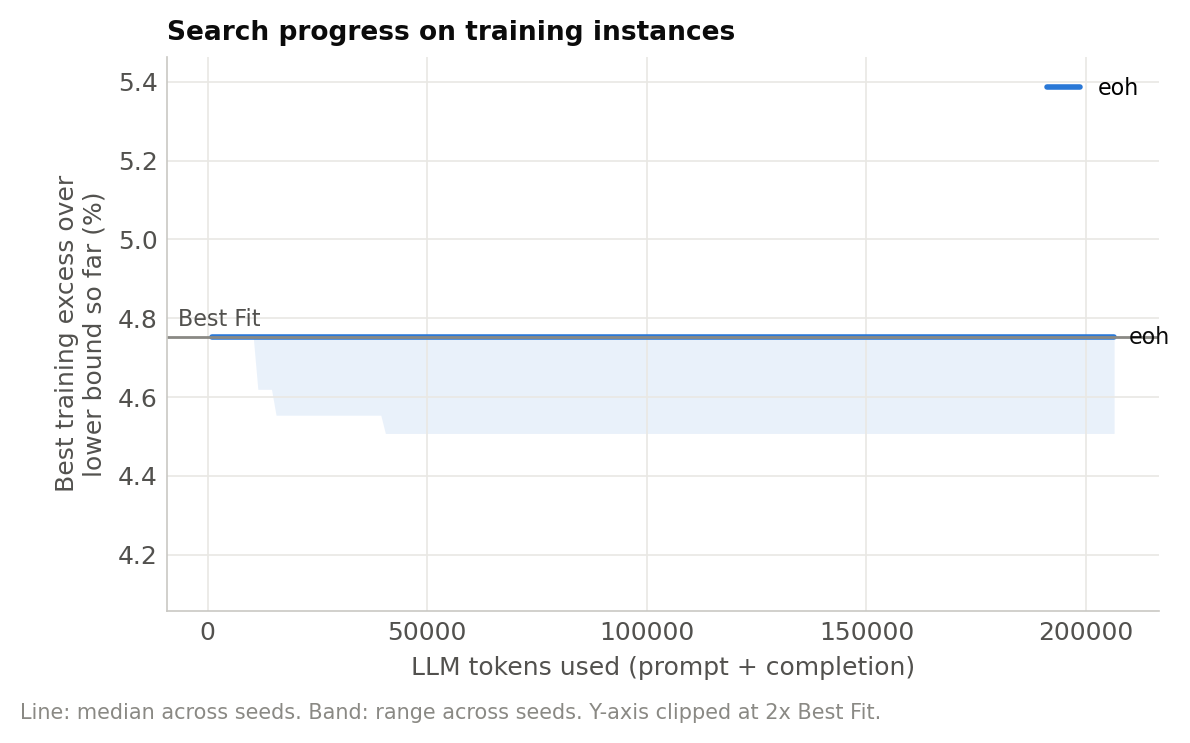

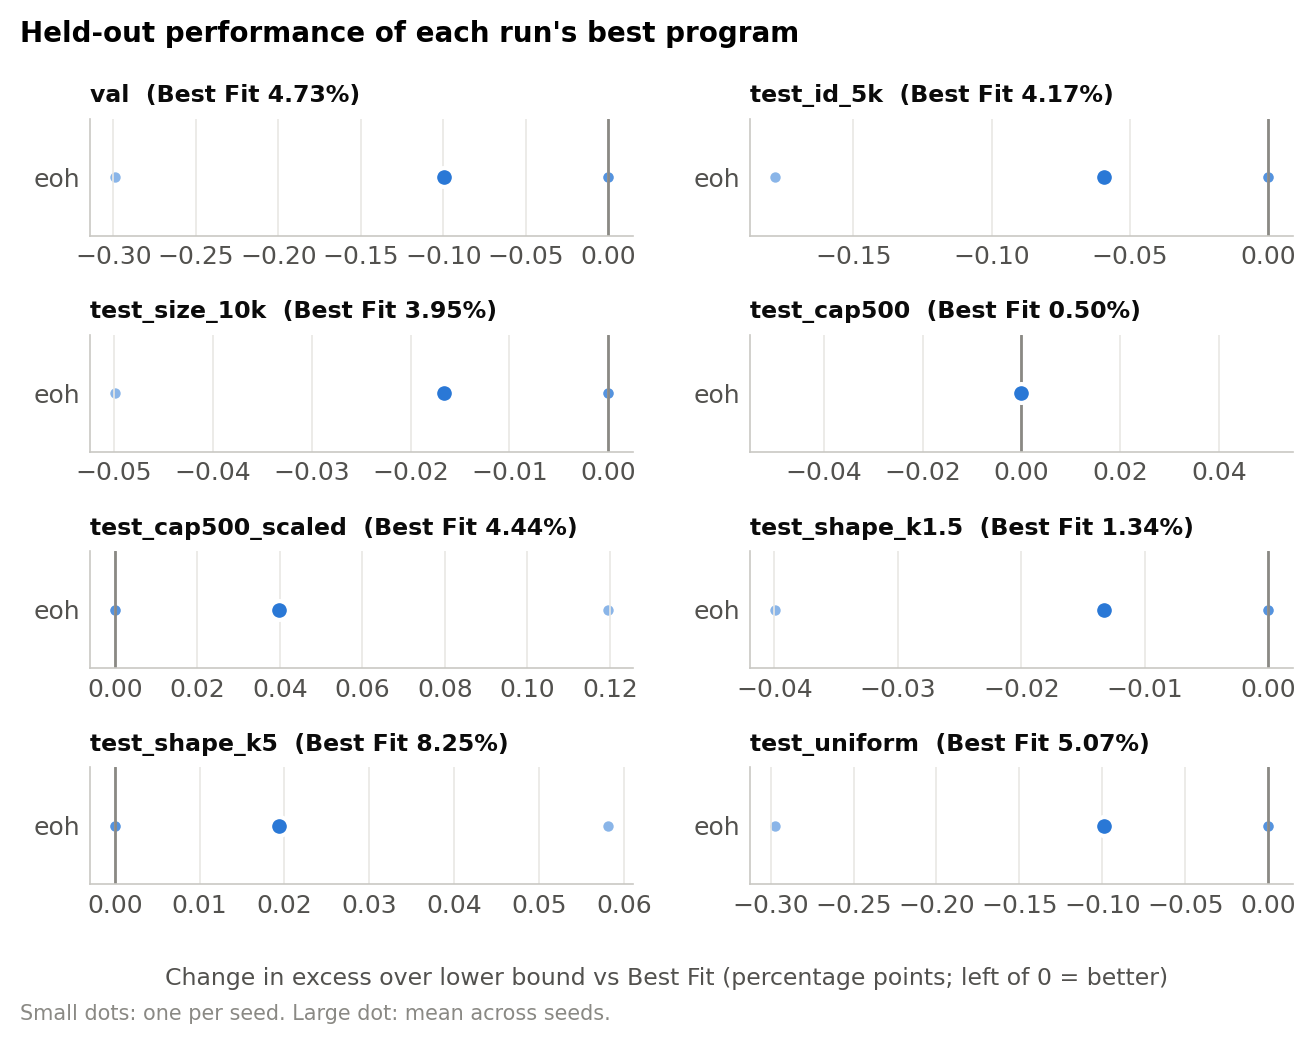

In [8]:
# 7d. Held-out evaluation of every finished seed: mean ± sd across seeds, plus tables and figures
summ = evaluate_final.main(CONFIG, **ARGS)
cell = lambda r: f"{100 * r.mean_excess:.2f}" + (f" ± {100 * r.sd_excess:.2f}" if r.runs > 1 else "")
display(summ.assign(cell=summ.apply(cell, axis=1)).pivot(index="label", columns="set", values="cell"))
display(summ[summ.label == "eoh"][["set", "runs", "delta_vs_bf_pp", "best_run", "worst_run", "win_vs_bf"]])
figs = summarise.main(CONFIG, **ARGS)
from IPython.display import Image
for name in ["convergence_evals", "convergence_tokens", "test_sets"]:
    display(Image(figs / f"{name}.png", width=650))

In [9]:
# # Why did no candidate succeed?
# print("stop reason:", s["stop_reason"], "| evals:", s["n_evals"], "| LLM calls:", s["n_llm_calls"],
#       "| minutes:", s["wall_minutes"])
# display(calls[["call", "latency_s", "status"]].tail(8))                    # did the API calls work?
# display(evals[["eval", "status", "wall_s", "error"]].head(10))             # did the candidates run?
# err = run / "error.txt"
# print(err.read_text()[-2000:] if err.exists() else "no error.txt") 

In [10]:
# import traceback
# from obpevo.llm import make_backend
# try:
#     print(make_backend(cfg["llm"]).complete("Say hi")[0][:200])
# except Exception:
#     traceback.print_exc()